<a href="https://colab.research.google.com/github/miriamamin1213-ux/ValidationSET/blob/main/HecktorRF.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Downloading...
From: https://drive.google.com/uc?id=1DGDH2e6dEkpdwwtCvH6ds1CwJT2Hdmkv
To: /content/HPV2025.xlsx
100%|██████████| 66.0k/66.0k [00:00<00:00, 12.3MB/s]


Dataset shape: (588, 10)
Predictors: ['Age', 'Gender', 'Tobacco Consumption', 'Alcohol Consumption', 'Performance Status', 'T-stage', 'N-stage', 'M-stage']

HPV class distribution:
HPV_Label
0     58
1    530
Name: count, dtype: int64

Split sizes:
Training: 381
Validation: 89
Test: 118

Training class counts:
HPV_Label
0     37
1    344
Name: count, dtype: int64

Validation class counts:
HPV_Label
0     9
1    80
Name: count, dtype: int64

Test class counts:
HPV_Label
0     12
1    106
Name: count, dtype: int64

Preprocessing complete.
Original predictors: 8
Encoded features: 23
Training matrix: (381, 23)
Validation matrix: (89, 23)
Test matrix: (118, 23)

Training class weights: {0: 5.148648648648648, 1: 0.5537790697674418}

Random Forest training complete.
Number of trees: 100
Random seed: 42

Best validation balanced accuracy: 0.7333
Selected probability threshold: 0.865

VALIDATION METRICS
Accuracy             0.7865
Balanced_Accuracy    0.7333
Precision            0.9552
Recall  

,Model,N_Train,N_Validation,N_Test,Original_Predictor_Count,Encoded_Feature_Count,N_Estimators,Random_State,Class_Weights,Validation_Accuracy,...,Validation_PR_AUC,Validation_Threshold,Test_Accuracy,Test_Balanced_Accuracy,Test_Precision,Test_Recall,Test_F1,Test_ROC_AUC,Test_PR_AUC,Test_Threshold
0,Random Forest,381,89,118,8,23,100,42,"{0: 5.148648648648648, 1: 0.5537790697674418}",0.786517,...,0.978178,0.865,0.779661,0.544811,0.908163,0.839623,0.872549,0.628145,0.935435,0.865


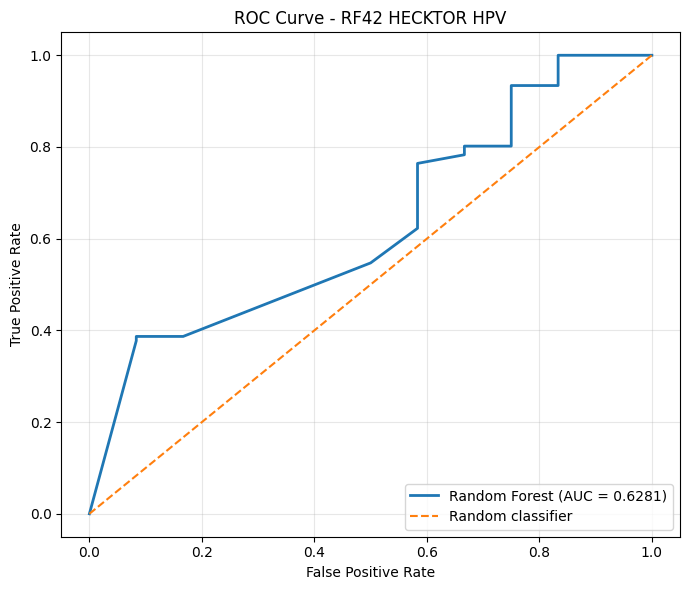

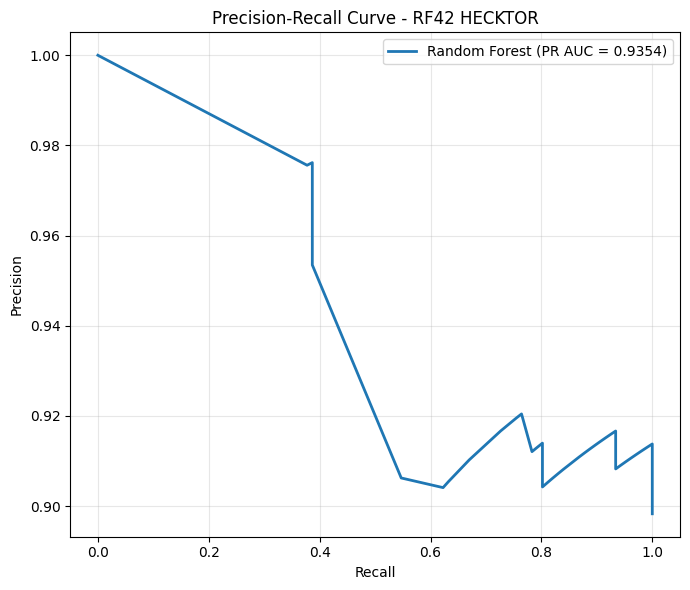


Feature Importance:
                feature  importance
                    Age    0.293463
             T-stage_T2    0.073043
             T-stage_T4    0.068713
             T-stage_T1    0.065032
Tobacco Consumption_0.0    0.061061
             T-stage_T3    0.052403
Tobacco Consumption_1.0    0.051209
             N-stage_N3    0.037551
             N-stage_N1    0.036794
 Performance Status_0.0    0.031500
Alcohol Consumption_0.0    0.029469
             N-stage_N2    0.028762
 Performance Status_1.0    0.026818
             N-stage_N0    0.026663
Alcohol Consumption_1.0    0.025013
             M-stage_M1    0.021731
             M-stage_M0    0.021516
               Gender_0    0.018150
               Gender_1    0.016994
 Performance Status_2.0    0.009843
 Performance Status_3.0    0.002429
             T-stage_T0    0.001371
 Performance Status_4.0    0.000471


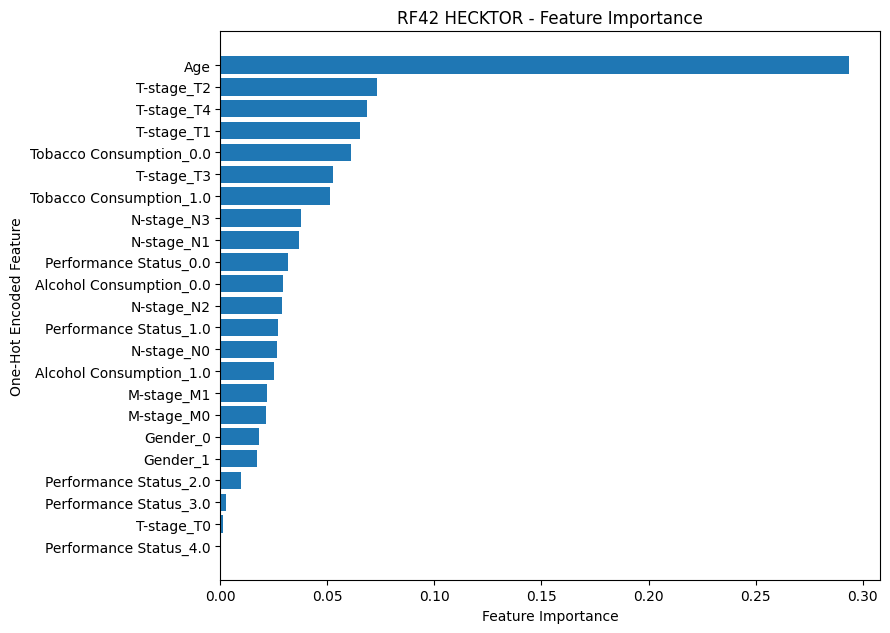


RF42 HECKTOR SUMMARY
Original predictors: 8
Encoded features: 23
Trees: 100
Random seed: 42
Train / Validation / Test: 381 / 89 / 118
Split: Stratified approximately 65 / 15 / 20
SMOTE: Not used
Categorical encoding: OneHotEncoder
Scaling: StandardScaler for Age
Threshold selected on validation set: 0.865

Final test metrics:
Accuracy             0.7797
Balanced_Accuracy    0.5448
Precision            0.9082
Recall               0.8396
F1                   0.8725
ROC_AUC              0.6281
PR_AUC               0.9354
Threshold            0.8650

Results saved in: /content/drive/MyDrive/RF_results_HECKTOR
Analysis complete.


In [1]:
# ============================================================
# RF42 HECKTOR — Random Forest HPV Classification
# Aligned with Hancock RF workflow
#
# Includes:
# - Stratified training / validation / test split
# - One-hot encoding of categorical variables
# - Preprocessing fitted on training data only
# - Validation-based classification threshold
# - Class weights calculated from training data
# - Final test evaluation and saved results
#
# Excludes: Relapse, RFS, Treatment
# ============================================================

!pip -q install gdown openpyxl

import os
import json
import random
import warnings
import joblib
import gdown
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)

warnings.filterwarnings("ignore", category=FutureWarning)

# ============================================================
# 1. REPRODUCIBILITY AND DATA LOADING
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

FILE_ID = "1DGDH2e6dEkpdwwtCvH6ds1CwJT2Hdmkv"
DATA_PATH = "HPV2025.xlsx"

if not os.path.exists(DATA_PATH):
    gdown.download(
        id=FILE_ID,
        output=DATA_PATH,
        quiet=False
    )

df = pd.read_excel(DATA_PATH)

# Use the same eight HECKTOR predictors as the revised workflow.
# Relapse, RFS and Treatment are deliberately excluded.
features = [
    "Age",
    "Gender",
    "Tobacco Consumption",
    "Alcohol Consumption",
    "Performance Status",
    "T-stage",
    "N-stage",
    "M-stage"
]

target_column = "HPV Status"

if target_column not in df.columns:
    raise KeyError(
        f"Target column '{target_column}' was not found. "
        f"Available columns: {df.columns.tolist()}"
    )

missing_features = [
    col for col in features if col not in df.columns
]

if missing_features:
    raise KeyError(
        f"These predictors are missing from the file: "
        f"{missing_features}"
    )

# Remove rows without a valid binary target.
df = df.dropna(subset=[target_column]).copy()

target_numeric = pd.to_numeric(
    df[target_column], errors="coerce"
)

df = df.loc[target_numeric.isin([0, 1])].copy()
df["HPV_Label"] = pd.to_numeric(
    df[target_column], errors="coerce"
).astype(int)

# Keep patient identifiers for test predictions, if available.
if "PatientID" in df.columns:
    patient_ids = df["PatientID"].copy()
else:
    patient_ids = pd.Series(
        df.index.astype(str),
        index=df.index
    )

# Create the modelling dataset.
model_df = df[features].copy()
model_df["HPV_Label"] = df["HPV_Label"]
model_df["patient_id"] = patient_ids

# Age is numeric; the remaining predictors are categorical.
numeric_features = ["Age"]

categorical_features = [
    col for col in features
    if col not in numeric_features
]

# Clean missing-value strings in categorical predictors.
missing_strings = {
    "", "nan", "none", "null", "na", "n/a"
}

for col in categorical_features:
    model_df[col] = model_df[col].apply(
        lambda value: (
            np.nan
            if pd.isna(value)
            or str(value).strip().lower() in missing_strings
            else str(value).strip()
        )
    )

model_df["Age"] = pd.to_numeric(
    model_df["Age"], errors="coerce"
)

if model_df["HPV_Label"].nunique() != 2:
    raise ValueError(
        "HPV Status must contain both classes: 0 and 1."
    )

if model_df["HPV_Label"].value_counts().min() < 3:
    raise ValueError(
        "Each class needs at least 3 observations "
        "for this stratified splitting procedure."
    )

print("Dataset shape:", model_df.shape)
print("Predictors:", features)
print("\nHPV class distribution:")
print(model_df["HPV_Label"].value_counts().sort_index())


# ============================================================
# 2. STRATIFIED TRAIN / VALIDATION / TEST SPLIT
# ============================================================

# First: reserve 20% for the final test set.
train_val, test = train_test_split(
    model_df,
    test_size=0.20,
    random_state=SEED,
    stratify=model_df["HPV_Label"]
)

# Then: split the remaining 80% into approximately
# 65% training and 15% validation of the full dataset.
train, val = train_test_split(
    train_val,
    test_size=0.1875,
    random_state=SEED,
    stratify=train_val["HPV_Label"]
)

print("\nSplit sizes:")
print("Training:", len(train))
print("Validation:", len(val))
print("Test:", len(test))

for name, subset in [
    ("Training", train),
    ("Validation", val),
    ("Test", test)
]:
    print(f"\n{name} class counts:")
    print(
        subset["HPV_Label"]
        .value_counts()
        .sort_index()
    )


# ============================================================
# 3. PREPROCESSING AND ONE-HOT ENCODING
# ============================================================

# Numeric variables:
# - Median imputation
# - Standard scaling
#
# Categorical variables:
# - Most-frequent imputation
# - One-hot encoding
#
# IMPORTANT:
# Fit preprocessing on the training set only.
# Validation and test data are transformed using that
# already-fitted preprocessing pipeline.

try:
    onehot = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )
except TypeError:
    # Compatibility with older scikit-learn versions.
    onehot = OneHotEncoder(
        handle_unknown="ignore",
        sparse=False
    )

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="most_frequent")
    ),
    ("onehot", onehot)
])

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_pipeline,
            numeric_features
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_features
        )
    ],
    remainder="drop",
    verbose_feature_names_out=False
)

X_train = preprocessor.fit_transform(train[features])
X_val = preprocessor.transform(val[features])
X_test = preprocessor.transform(test[features])

y_train = train["HPV_Label"].to_numpy()
y_val = val["HPV_Label"].to_numpy()
y_test = test["HPV_Label"].to_numpy()

test_ids = test["patient_id"].to_numpy()

try:
    encoded_feature_names = (
        preprocessor.get_feature_names_out().tolist()
    )
except (AttributeError, TypeError):
    encoded_feature_names = [
        f"encoded_feature_{i}"
        for i in range(X_train.shape[1])
    ]

print("\nPreprocessing complete.")
print("Original predictors:", len(features))
print("Encoded features:", X_train.shape[1])
print("Training matrix:", X_train.shape)
print("Validation matrix:", X_val.shape)
print("Test matrix:", X_test.shape)


# ============================================================
# 4. CLASS WEIGHTS FROM THE TRAINING DATA
# ============================================================

# No SMOTE is applied.
# Class weights are calculated using training labels only.

class_counts = np.bincount(
    y_train,
    minlength=2
)

if np.any(class_counts == 0):
    raise ValueError(
        "Both HPV classes must be present in the training set."
    )

class_weights = {
    class_label: len(y_train) / (
        2 * class_counts[class_label]
    )
    for class_label in range(2)
}

class_weights = {
    key: float(value)
    for key, value in class_weights.items()
}

print("\nTraining class weights:", class_weights)


# ============================================================
# 5. TRAIN RANDOM FOREST
# ============================================================

model = RandomForestClassifier(
    n_estimators=100,
    class_weight=class_weights,
    random_state=SEED
)

model.fit(X_train, y_train)

print("\nRandom Forest training complete.")
print("Number of trees:", model.n_estimators)
print("Random seed:", SEED)


# ============================================================
# 6. SELECT CLASSIFICATION THRESHOLD USING VALIDATION DATA
# ============================================================

# The validation set is used to select the probability
# threshold. The test set is NOT used for threshold tuning.
#
# Select the threshold with the highest validation
# balanced accuracy. If tied, choose the value closest
# to 0.5.

val_prob = model.predict_proba(X_val)[:, 1]

thresholds = np.linspace(
    0.10,
    0.90,
    161
)

validation_scores = []

for threshold in thresholds:
    val_prediction = (
        val_prob >= threshold
    ).astype(int)

    score = balanced_accuracy_score(
        y_val,
        val_prediction
    )

    validation_scores.append(score)

best_score = max(validation_scores)

best_threshold = min(
    [
        threshold
        for threshold, score in zip(
            thresholds, validation_scores
        )
        if score == best_score
    ],
    key=lambda threshold: abs(threshold - 0.5)
)

best_threshold = float(best_threshold)

print(
    "\nBest validation balanced accuracy:",
    round(best_score, 4)
)

print(
    "Selected probability threshold:",
    round(best_threshold, 3)
)


# ============================================================
# 7. METRICS FUNCTION
# ============================================================

def calculate_metrics(
    y_true,
    probabilities,
    predictions,
    threshold
):
    return {
        "Accuracy": accuracy_score(
            y_true, predictions
        ),
        "Balanced_Accuracy": balanced_accuracy_score(
            y_true, predictions
        ),
        "Precision": precision_score(
            y_true,
            predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            y_true,
            predictions,
            zero_division=0
        ),
        "F1": f1_score(
            y_true,
            predictions,
            zero_division=0
        ),
        "ROC_AUC": (
            roc_auc_score(y_true, probabilities)
            if len(np.unique(y_true)) == 2
            else np.nan
        ),
        "PR_AUC": (
            average_precision_score(
                y_true, probabilities
            )
            if len(np.unique(y_true)) == 2
            else np.nan
        ),
        "Threshold": float(threshold)
    }


# Validation performance at the selected threshold.
val_pred = (
    val_prob >= best_threshold
).astype(int)

val_metrics = calculate_metrics(
    y_val,
    val_prob,
    val_pred,
    best_threshold
)

print("\nVALIDATION METRICS")
print(
    pd.Series(val_metrics).round(4).to_string()
)


# ============================================================
# 8. FINAL TEST EVALUATION
# ============================================================

# Evaluate the held-out test set once using the threshold
# selected from the validation set.

test_prob = model.predict_proba(X_test)[:, 1]

test_pred = (
    test_prob >= best_threshold
).astype(int)

test_metrics = calculate_metrics(
    y_test,
    test_prob,
    test_pred,
    best_threshold
)

print("\n===================================")
print("FINAL TEST METRICS")
print("===================================")

print(
    pd.Series(test_metrics).round(4).to_string()
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test,
        test_pred,
        labels=[0, 1]
    )
)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        test_pred,
        labels=[0, 1],
        target_names=[
            "HPV Negative",
            "HPV Positive"
        ],
        zero_division=0
    )
)


# ============================================================
# 9. CREATE OUTPUT FOLDER
# ============================================================

try:
    from google.colab import drive
    drive.mount("/content/drive")

    OUT_DIR = (
        "/content/drive/MyDrive/RF_results_HECKTOR"
    )
except ImportError:
    OUT_DIR = "RF_results_HECKTOR"

os.makedirs(OUT_DIR, exist_ok=True)


# ============================================================
# 10. SAVE METRICS, PREDICTIONS AND SETTINGS
# ============================================================

results = {
    "Model": "Random Forest",
    "N_Train": len(y_train),
    "N_Validation": len(y_val),
    "N_Test": len(y_test),
    "Original_Predictor_Count": len(features),
    "Encoded_Feature_Count": int(X_train.shape[1]),
    "N_Estimators": model.n_estimators,
    "Random_State": SEED,
    "Class_Weights": str(class_weights)
}

results.update({
    f"Validation_{key}": value
    for key, value in val_metrics.items()
})

results.update({
    f"Test_{key}": value
    for key, value in test_metrics.items()
})

results_df = pd.DataFrame([results])

results_df.to_csv(
    os.path.join(OUT_DIR, "metrics.csv"),
    index=False
)

predictions_df = pd.DataFrame({
    "patient_id": test_ids,
    "y_true": y_test,
    "probability_positive": test_prob,
    "prediction": test_pred
})

predictions_df.to_csv(
    os.path.join(OUT_DIR, "test_predictions.csv"),
    index=False
)

settings = {
    "model": "RandomForestClassifier",
    "seed": SEED,
    "features": features,
    "target_column": target_column,
    "target_classes": [0, 1],
    "selected_threshold": best_threshold,
    "validation_balanced_accuracy": float(best_score),
    "class_weights": class_weights,
    "smote": False,
    "split": {
        "training_rows": len(train),
        "validation_rows": len(val),
        "test_rows": len(test),
        "approximate_proportions": {
            "training": 0.65,
            "validation": 0.15,
            "test": 0.20
        },
        "stratified": True,
        "random_state": SEED
    },
    "preprocessing": {
        "numeric": (
            "Median imputation and StandardScaler; "
            "fitted on training data only"
        ),
        "categorical": (
            "Most-frequent imputation and OneHotEncoder "
            "with handle_unknown='ignore'; fitted on "
            "training data only"
        )
    },
    "encoded_feature_names": encoded_feature_names
}

with open(
    os.path.join(OUT_DIR, "settings.json"),
    "w",
    encoding="utf-8"
) as file:
    json.dump(settings, file, indent=2)

joblib.dump(
    {
        "model": model,
        "preprocessor": preprocessor,
        "features": features,
        "numeric_features": numeric_features,
        "categorical_features": categorical_features,
        "target_column": target_column,
        "threshold": best_threshold,
        "encoded_feature_names": encoded_feature_names
    },
    os.path.join(
        OUT_DIR,
        "RF42_HECKTOR_model.joblib"
    )
)

print("\nSaved metrics, predictions, settings and model.")
display(results_df)


# ============================================================
# 11. ROC CURVE — TEST SET
# ============================================================

fpr, tpr, _ = roc_curve(y_test, test_prob)
roc_auc = roc_auc_score(y_test, test_prob)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"Random Forest (AUC = {roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - RF42 HECKTOR HPV")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(OUT_DIR, "roc_curve.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 12. PRECISION-RECALL CURVE — TEST SET
# ============================================================

precision_values, recall_values, _ = (
    precision_recall_curve(y_test, test_prob)
)

pr_auc = average_precision_score(
    y_test, test_prob
)

plt.figure(figsize=(7, 6))

plt.plot(
    recall_values,
    precision_values,
    linewidth=2,
    label=f"Random Forest (PR AUC = {pr_auc:.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - RF42 HECKTOR")
plt.legend(loc="best")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(
        OUT_DIR,
        "precision_recall_curve.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 13. ONE-HOT ENCODED FEATURE IMPORTANCE
# ============================================================

feature_importance = pd.DataFrame({
    "feature": encoded_feature_names,
    "importance": model.feature_importances_
}).sort_values(
    "importance",
    ascending=False
)

feature_importance.to_csv(
    os.path.join(OUT_DIR, "feature_importance.csv"),
    index=False
)

print("\nFeature Importance:")
print(
    feature_importance.to_string(index=False)
)

top_n = min(25, len(feature_importance))

plot_importance = (
    feature_importance
    .head(top_n)
    .sort_values("importance")
)

plt.figure(
    figsize=(9, max(5, 0.28 * top_n))
)

plt.barh(
    plot_importance["feature"],
    plot_importance["importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("One-Hot Encoded Feature")
plt.title("RF42 HECKTOR - Feature Importance")
plt.tight_layout()

plt.savefig(
    os.path.join(
        OUT_DIR,
        "feature_importance.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 14. FINAL SUMMARY
# ============================================================

print("\n===================================")
print("RF42 HECKTOR SUMMARY")
print("===================================")

print("Original predictors:", len(features))
print("Encoded features:", X_train.shape[1])
print("Trees:", model.n_estimators)
print("Random seed:", SEED)

print(
    "Train / Validation / Test:",
    f"{len(train)} / {len(val)} / {len(test)}"
)

print("Split: Stratified approximately 65 / 15 / 20")
print("SMOTE: Not used")
print("Categorical encoding: OneHotEncoder")
print("Scaling: StandardScaler for Age")
print("Threshold selected on validation set:", best_threshold)

print("\nFinal test metrics:")
print(
    pd.Series(test_metrics).round(4).to_string()
)

print("\nResults saved in:", OUT_DIR)
print("Analysis complete.")